# Notebook 05 — Training a Transformer for NLP

## Mục tiêu

Huấn luyện Transformer để dự đoán ký tự tiếp theo trong văn bản.

## Quy trình

1. Dataset Preparation
2. Character-Level Tokenization
3. Vocabulary Construction
4. Train/Validation Split
5. Sequence Preparation
6. Transformer Training
7. Evaluation
8. Text Generation

In [1]:
import math
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

PyTorch version: 2.14.1+cpu
Device: cpu


### Prediction

- PyTorch sẽ cung cấp các thành phần cần thiết để xây dựng và huấn luyện mô hình.
- Matplotlib được sử dụng để trực quan hóa Training Loss và Validation Loss.
- Dataset sẽ được xử lý thành các chuỗi token ID.

## Dataset Preparation

Sử dụng Tiny Shakespeare làm dữ liệu huấn luyện.

Mục tiêu:
- Tải dữ liệu văn bản.
- Đọc nội dung.
- Quan sát kích thước và một phần dữ liệu.

In [2]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

file_path = "tinyshakespeare.txt"

urllib.request.urlretrieve(url, file_path)

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

print("Dataset downloaded successfully.")
print("Number of characters:", len(text))
print("\nFirst 500 characters:\n")
print(text[:500])

Dataset downloaded successfully.
Number of characters: 1115394

First 500 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


### Observation

Ghi nhận:
- Tổng số ký tự trong dataset.
- Nội dung văn bản có cấu trúc như thế nào.
- Các ký tự xuất hiện bao gồm chữ cái, dấu câu, khoảng trắng và ký tự xuống dòng.

Dataset hiện tại là văn bản thô, chưa được chuyển thành dạng số để Transformer xử lý.

## Character-Level Tokenization

Xây dựng bộ mã hóa ký tự:

- Mỗi ký tự duy nhất tương ứng với một token ID.
- char_to_id: chuyển ký tự thành số nguyên.
- id_to_char: chuyển số nguyên thành ký tự.

Mục tiêu: Chuyển văn bản thành chuỗi số nguyên để Transformer có thể xử lý.

In [3]:
vocab = sorted(list(set(text)))

vocab_size = len(vocab)

char_to_id = {char: i for i, char in enumerate(vocab)}
id_to_char = {i: char for i, char in enumerate(vocab)}

print("Vocabulary size:", vocab_size)
print("First 30 characters:", vocab[:30])

sample = text[:20]
encoded = [char_to_id[char] for char in sample]
decoded = "".join([id_to_char[i] for i in encoded])

print("\nOriginal text:", repr(sample))
print("Encoded:", encoded)
print("Decoded:", repr(decoded))
print("Reconstruction correct:", sample == decoded)

Vocabulary size: 65
First 30 characters: ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q']

Original text: 'First Citizen:\nBefor'
Encoded: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56]
Decoded: 'First Citizen:\nBefor'
Reconstruction correct: True


### Observation

Ghi nhận:

- Vocabulary size: số lượng ký tự duy nhất.
- Encoded: biểu diễn văn bản dưới dạng số nguyên.
- Decoded: khôi phục chuỗi ký tự ban đầu.

Nếu Reconstruction correct là True, quá trình mã hóa và giải mã hoạt động chính xác.

## Encode Dataset

Chuyển toàn bộ văn bản thành một dãy số nguyên.

Kết quả:
- Mỗi ký tự tương ứng với một token ID.
- Dữ liệu được lưu dưới dạng PyTorch Tensor.
- Tensor này sẽ là đầu vào cho quá trình huấn luyện.

In [4]:
data = torch.tensor(
    [char_to_id[char] for char in text],
    dtype=torch.long
)

print("Data shape:", data.shape)
print("Data type:", data.dtype)
print("First 50 token IDs:", data[:50])
print("Number of tokens:", len(data))

Data shape: torch.Size([1115394])
Data type: torch.int64
First 50 token IDs: tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56])
Number of tokens: 1115394


### Observation

Ghi nhận:
- Shape của Tensor.
- Kiểu dữ liệu.
- Số lượng token.

Vì sử dụng Character-Level Tokenization, mỗi ký tự trong văn bản tương ứng với một token.

## Train/Validation Split

Chia dataset thành hai phần:

- Training set: 90%
- Validation set: 10%

Dữ liệu được chia theo thứ tự ban đầu, không random shuffle.

Mục tiêu: Đánh giá khả năng dự đoán trên một phần văn bản không xuất hiện trong tập huấn luyện.

In [5]:
split_index = int(0.9 * len(data))

train_data = data[:split_index]
val_data = data[split_index:]

print("Total tokens:", len(data))
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))

print("Training ratio:", len(train_data) / len(data))
print("Validation ratio:", len(val_data) / len(data))

Total tokens: 1115394
Training tokens: 1003854
Validation tokens: 111540
Training ratio: 0.8999994620734916
Validation ratio: 0.10000053792650848


### Observation

Ghi nhận số lượng token trong từng tập.

Training set được sử dụng để học quy luật ngôn ngữ.

Validation set được sử dụng để theo dõi khả năng dự đoán trên dữ liệu chưa dùng để cập nhật trọng số.

## Training Sequences

Tạo các batch dữ liệu cho bài toán Next-Character Prediction.

Mỗi mẫu gồm:

- x: chuỗi ký tự đầu vào.
- y: chuỗi mục tiêu, được dịch sang phải một vị trí so với x.

Ví dụ:

x = [H, E, L, L, O]
y = [E, L, L, O, !]

Mô hình học cách dự đoán ký tự tiếp theo tại mỗi vị trí.

In [6]:
block_size = 64
batch_size = 32

def get_batch(split):
    source = train_data if split == "train" else val_data

    indices = torch.randint(
        len(source) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size]
        for i in indices
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1]
        for i in indices
    ])

    return x, y

x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nInput example:")
print(x[0])

print("\nTarget example:")
print(y[0])

print("\nInput decoded:")
print("".join(id_to_char[i.item()] for i in x[0]))

print("\nTarget decoded:")
print("".join(id_to_char[i.item()] for i in y[0]))

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])

Input example:
tensor([47, 45, 46, 58,  8,  0,  0, 34, 21, 30, 19, 21, 24, 21, 13, 10,  0, 21,
        52, 42, 43, 43, 42,  6,  1, 51, 39, 42, 39, 51, 12,  0,  0, 34, 13, 24,
        17, 30, 21, 13, 10,  0, 21, 52,  1, 43, 39, 56, 52, 43, 57, 58,  6,  1,
        47, 58,  5, 57,  1, 58, 56, 59, 43, 11])

Target example:
tensor([45, 46, 58,  8,  0,  0, 34, 21, 30, 19, 21, 24, 21, 13, 10,  0, 21, 52,
        42, 43, 43, 42,  6,  1, 51, 39, 42, 39, 51, 12,  0,  0, 34, 13, 24, 17,
        30, 21, 13, 10,  0, 21, 52,  1, 43, 39, 56, 52, 43, 57, 58,  6,  1, 47,
        58,  5, 57,  1, 58, 56, 59, 43, 11,  1])

Input decoded:
ight.

VIRGILIA:
Indeed, madam?

VALERIA:
In earnest, it's true;

Target decoded:
ght.

VIRGILIA:
Indeed, madam?

VALERIA:
In earnest, it's true; 


### Observation

Kiểm tra:

- Input và Target có cùng shape `(32, 64)`.
- Target được dịch sang trước Input đúng một ký tự.
- Mỗi batch chứa 32 chuỗi, mỗi chuỗi dài 64 ký tự.

Đây là cấu trúc dữ liệu cho bài toán dự đoán ký tự tiếp theo.

## Causal Self-Attention

Trong bài toán dự đoán ký tự tiếp theo, tại vị trí t, mô hình chỉ được phép sử dụng thông tin từ các vị trí:

0, 1, 2, ..., t

Không được phép nhìn thấy các vị trí phía sau t.

Sử dụng Causal Mask:

- Vùng tam giác dưới: được phép Attention.
- Vùng tam giác trên: bị chặn bằng -inf trước Softmax.

Mục tiêu: Đảm bảo mô hình không sử dụng thông tin tương lai.

In [7]:
sequence_length = 5

causal_mask = torch.tril(
    torch.ones(sequence_length, sequence_length)
)

print(causal_mask)

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])


### Observation

Ma trận Causal Mask có dạng tam giác dưới.

- Hàng 0 chỉ nhìn thấy vị trí 0.
- Hàng 1 nhìn thấy vị trí 0 và 1.
- Hàng 2 nhìn thấy vị trí 0, 1 và 2.
- Các vị trí tương lai bị chặn.

Cơ chế này bảo đảm tính nhân quả trong quá trình dự đoán.

## Causal Multi-Head Attention

Xây dựng Multi-Head Attention có hỗ trợ Causal Mask.

Quy trình:

1. Tạo Query, Key và Value.
2. Chia thành nhiều Attention Heads.
3. Tính Attention Scores.
4. Chặn các vị trí tương lai bằng Causal Mask.
5. Áp dụng Softmax.
6. Tính Attention Output.
7. Ghép các Heads và chiếu qua Output Layer.

In [8]:
class CausalMultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch_size, sequence_length, _ = x.shape

        x = x.reshape(
            batch_size,
            sequence_length,
            self.num_heads,
            self.d_k
        )

        return x.transpose(1, 2)

    def forward(self, x):
        batch_size, sequence_length, _ = x.shape

        Q = self.split_heads(self.W_q(x))
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores / math.sqrt(self.d_k)

        mask = torch.tril(
            torch.ones(sequence_length, sequence_length, device=x.device)
        )

        scores = scores.masked_fill(mask == 0, float("-inf"))

        weights = F.softmax(scores, dim=-1)

        output = torch.matmul(weights, V)
        output = output.transpose(1, 2).contiguous()

        output = output.reshape(
            batch_size,
            sequence_length,
            self.d_model
        )

        output = self.W_o(output)

        return output, weights

In [9]:
d_model = 64
num_heads = 4
batch_size = 2
sequence_length = 5

attention = CausalMultiHeadAttention(d_model, num_heads)

x_test = torch.randn(batch_size, sequence_length, d_model)

output, weights = attention(x_test)

print("Input shape:", x_test.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)

print("\nAttention weights of first head:")
print(weights[0, 0])

Input shape: torch.Size([2, 5, 64])
Output shape: torch.Size([2, 5, 64])
Attention weights shape: torch.Size([2, 4, 5, 5])

Attention weights of first head:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5022, 0.4978, 0.0000, 0.0000, 0.0000],
        [0.3398, 0.4579, 0.2023, 0.0000, 0.0000],
        [0.2916, 0.3397, 0.1469, 0.2218, 0.0000],
        [0.2286, 0.2729, 0.1027, 0.2578, 0.1380]], grad_fn=<SelectBackward0>)


### Observation

Kiểm tra:

- Input và Output có cùng shape.
- Attention Weights có shape `(batch_size, num_heads, sequence_length, sequence_length)`.
- Các vị trí tương lai có Attention Weight bằng 0.
- Tổng Attention Weight trên mỗi hàng bằng 1.

Nếu các điều kiện trên được thỏa mãn, Causal Multi-Head Attention hoạt động đúng.

## Causal Transformer Encoder Block

Xây dựng một Transformer Block dành cho Autoregressive Language Modeling.

Kiến trúc:

Input
  ↓
Causal Multi-Head Attention
  ↓
Residual Connection + LayerNorm
  ↓
Feed-Forward Network
  ↓
Residual Connection + LayerNorm
  ↓
Output

Khác với Encoder ở Notebook 04, Attention trong Block này sử dụng Causal Mask.

In [10]:
class FeedForwardNetwork(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()

        self.linear1 = nn.Linear(d_model, d_ff)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        x = self.linear1(x)
        x = self.relu(x)
        x = self.linear2(x)
        return x


class CausalTransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff):
        super().__init__()

        self.attention = CausalMultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)

        self.ffn = FeedForwardNetwork(d_model, d_ff)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attention_output, weights = self.attention(x)

        x = self.norm1(x + attention_output)

        ffn_output = self.ffn(x)

        output = self.norm2(x + ffn_output)

        return output, weights

In [11]:
d_model = 64
num_heads = 4
d_ff = 256

block = CausalTransformerBlock(d_model, num_heads, d_ff)

x_test = torch.randn(2, 5, d_model)

output, weights = block(x_test)

print("Input shape:", x_test.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)
print("Total parameters:", sum(p.numel() for p in block.parameters()))

Input shape: torch.Size([2, 5, 64])
Output shape: torch.Size([2, 5, 64])
Attention weights shape: torch.Size([2, 4, 5, 5])
Total parameters: 49984


## Transformer Language Model

Xây dựng mô hình hoàn chỉnh gồm:

- Token Embedding
- Positional Encoding
- Causal Transformer Blocks
- Output Linear Layer

Cấu hình ban đầu:

- Vocabulary Size: 65
- d_model: 64
- num_heads: 4
- d_ff: 256
- num_layers: 2
- block_size: 64

Đầu ra tại mỗi vị trí là 65 logits, tương ứng với 65 ký tự có thể được dự đoán.

In [12]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class TransformerLanguageModel(nn.Module):
    def __init__(
            self,
            vocab_size,
            d_model,
            num_heads,
            d_ff,
            num_layers,
            max_len
    ):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, d_model)
        self.positional_encoding = PositionalEncoding(d_model, max_len)

        self.blocks = nn.ModuleList([
            CausalTransformerBlock(d_model, num_heads, d_ff)
            for _ in range(num_layers)
        ])

        self.output_layer = nn.Linear(d_model, vocab_size)

    def forward(self, token_ids):
        x = self.embedding(token_ids)
        x = self.positional_encoding(x)

        attention_weights = []

        for block in self.blocks:
            x, weights = block(x)
            attention_weights.append(weights)

        logits = self.output_layer(x)

        return logits, attention_weights

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TransformerLanguageModel(
    vocab_size=vocab_size,
    d_model=64,
    num_heads=4,
    d_ff=256,
    num_layers=2,
    max_len=block_size
).to(device)

x_test, y_test = get_batch("train")

x_test = x_test.to(device)

logits, attention_weights = model(x_test)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Device:", device)
print("Input shape:", x_test.shape)
print("Logits shape:", logits.shape)
print("Number of Transformer Blocks:", len(model.blocks))
print("Number of Attention Weight Tensors:", len(attention_weights))
print("Total parameters:", total_parameters)

Device: cpu
Input shape: torch.Size([2, 64])
Logits shape: torch.Size([2, 64, 65])
Number of Transformer Blocks: 2
Number of Attention Weight Tensors: 2
Total parameters: 108353


## Loss and Backpropagation

Sử dụng Cross Entropy Loss cho bài toán dự đoán ký tự tiếp theo.

Logits:
(batch_size, sequence_length, vocab_size)

Targets:
(batch_size, sequence_length)

PyTorch CrossEntropyLoss yêu cầu đưa logits về dạng:

(batch_size * sequence_length, vocab_size)

Mục tiêu: Kiểm tra Loss và Gradient trước khi huấn luyện.

In [14]:
model.train()

x, y = get_batch("train")

x = x.to(device)
y = y.to(device)

logits, _ = model(x)

loss = F.cross_entropy(
    logits.reshape(-1, vocab_size),
    y.reshape(-1)
)

model.zero_grad()
loss.backward()

print("Loss:", loss.item())

print("\nEmbedding gradient:", model.embedding.weight.grad.norm().item())
print("Attention gradient:", model.blocks[0].attention.W_q.weight.grad.norm().item())
print("FFN gradient:", model.blocks[0].ffn.linear1.weight.grad.norm().item())
print("Output layer gradient:", model.output_layer.weight.grad.norm().item())

Loss: 4.4060211181640625

Embedding gradient: 0.05198357626795769
Attention gradient: 0.03416178748011589
FFN gradient: 0.18697819113731384
Output layer gradient: 1.1694122552871704


### Observation

Ghi nhận:

- Cross Entropy Loss phải là một giá trị hữu hạn.
- Gradient của Embedding phải tồn tại.
- Gradient của Attention phải tồn tại.
- Gradient của FFN phải tồn tại.
- Gradient của Output Layer phải tồn tại.

Nếu các Gradient đều khác 0, quá trình lan truyền ngược hoạt động qua các thành phần chính của mô hình.

## Training Configuration

Thiết lập:

- Optimizer: AdamW
- Learning Rate: 0.001
- Batch Size: 32
- Block Size: 64
- Training Iterations: 500

Training Loss được dùng để theo dõi khả năng học trên tập huấn luyện.

Validation Loss được dùng để theo dõi khả năng dự đoán trên dữ liệu validation.

Mục tiêu: Quan sát Loss thay đổi trong quá trình huấn luyện.

In [15]:
learning_rate = 0.001
max_iters = 500
eval_interval = 100
eval_iters = 20

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

@torch.no_grad()
def estimate_loss():
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_iters):
            x, y = get_batch(split)

            x = x.to(device)
            y = y.to(device)

            logits, _ = model(x)

            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )

            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()

    return results

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)
print("Training iterations:", max_iters)
print("Evaluation interval:", eval_interval)

Optimizer: AdamW
Learning rate: 0.001
Training iterations: 500
Evaluation interval: 100


### Observation

Xác nhận cấu hình huấn luyện trước khi chạy.

Lưu ý: Mỗi lần đánh giá Loss sử dụng nhiều batch ngẫu nhiên để giảm ảnh hưởng của một batch đơn lẻ.

## Transformer Training

Thực hiện quá trình huấn luyện trong 500 iterations.

Tại mỗi iteration:

1. Lấy một batch dữ liệu.
2. Forward propagation.
3. Tính Cross Entropy Loss.
4. Backpropagation.
5. Cập nhật tham số bằng AdamW.

Mỗi 100 iterations, đánh giá Training Loss và Validation Loss.

In [16]:
import time

train_losses = []
val_losses = []
iterations = []

start_time = time.time()

for iteration in range(max_iters):

    x, y = get_batch("train")

    x = x.to(device)
    y = y.to(device)

    logits, _ = model(x)

    loss = F.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if (iteration + 1) % eval_interval == 0:
        losses = estimate_loss()

        iterations.append(iteration + 1)
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        elapsed = time.time() - start_time

        print(
            f"Iteration {iteration + 1}/{max_iters} | "
            f"Train Loss: {losses['train']:.4f} | "
            f"Val Loss: {losses['val']:.4f} | "
            f"Time: {elapsed:.2f}s"
        )

total_time = time.time() - start_time

print("\nTraining completed.")
print("Total training time:", round(total_time, 2), "seconds")

Iteration 500/500 | Train Loss: 2.4870 | Val Loss: 2.5168 | Time: 5.48s

Training completed.
Total training time: 5.48 seconds


## Learning Curve

Trực quan hóa quá trình huấn luyện bằng hai đường:

- Training Loss
- Validation Loss

Mục tiêu:
- Quan sát xu hướng giảm Loss.
- So sánh khả năng học và khả năng tổng quát hóa.
- Phát hiện dấu hiệu overfitting.

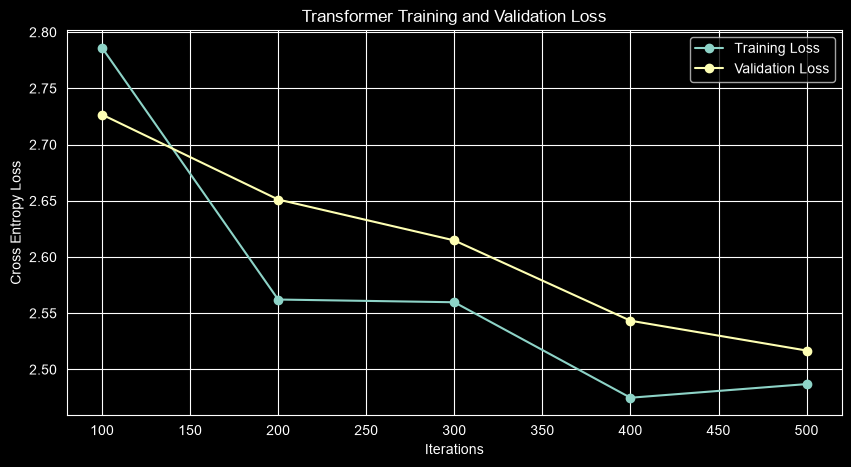

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(iterations, train_losses, marker="o", label="Training Loss")
plt.plot(iterations, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Iterations")
plt.ylabel("Cross Entropy Loss")
plt.title("Transformer Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

### Observation

Phân tích biểu đồ:

1. Training Loss có xu hướng giảm.
2. Validation Loss có xu hướng giảm.
3. Khoảng cách giữa hai đường Loss tương đối nhỏ.
4. Chưa xuất hiện hiện tượng Validation Loss tăng liên tục trong khi Training Loss giảm.

Kết luận: Mô hình đang học được đặc trưng từ dữ liệu và chưa có dấu hiệu overfitting rõ ràng trong 500 iterations.

## Text Generation — Greedy Decoding

Greedy Decoding lựa chọn token có xác suất cao nhất tại mỗi bước.

Quy trình:

1. Nhận Prompt.
2. Đưa Prompt qua Transformer.
3. Lấy Logits tại vị trí cuối cùng.
4. Chọn token có Logit lớn nhất bằng Argmax.
5. Thêm token mới vào chuỗi.
6. Lặp lại để tạo văn bản.

Mục tiêu: Kiểm tra khả năng sinh văn bản của mô hình đã huấn luyện.

In [19]:
@torch.no_grad()
def generate_greedy(model, prompt, max_new_tokens):
    model.eval()

    token_ids = torch.tensor(
        [[char_to_id[char] for char in prompt]],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        input_ids = token_ids[:, -block_size:]

        logits, _ = model(input_ids)

        next_token_logits = logits[:, -1, :]

        next_token = torch.argmax(
            next_token_logits,
            dim=-1,
            keepdim=True
        )

        token_ids = torch.cat(
            [token_ids, next_token],
            dim=1
        )

    generated_text = "".join(
        id_to_char[token_id]
        for token_id in token_ids[0].tolist()
    )

    return generated_text

In [20]:
prompt = "First Citizen:\n"

generated_text = generate_greedy(
    model,
    prompt,
    max_new_tokens=300
)

print(generated_text)

First Citizen:
And t the the the the the the the the t the ther ther the t t t ther ther ther the the t the the t the the the t the t the ther the the t t t ther therer the t t t therer the the t t the the ther the t t ther ther the the t the the t the the t ther the t the the t ther ther the the t t the ther ther


### Observation

Đánh giá văn bản được sinh ra:

- Văn bản có tiếp tục từ Prompt không?
- Có xuất hiện các từ tiếng Anh hợp lệ không?
- Có hình thành câu và đoạn hội thoại không?
- Có lặp lại một từ hoặc ký tự quá nhiều không?
- Văn bản có mang phong cách hội thoại kịch Shakespeare không?

Lưu ý: Mô hình mới được huấn luyện 500 iterations nên chất lượng văn bản có thể còn hạn chế.

## Text Generation — Temperature Sampling

Temperature Sampling sử dụng phân phối xác suất để chọn token tiếp theo.

Khác với Greedy Decoding:
- Greedy: luôn chọn token có xác suất cao nhất.
- Sampling: chọn token ngẫu nhiên theo xác suất.

Temperature điều chỉnh mức độ phân tán của phân phối xác suất.

Mục tiêu: So sánh khả năng sinh văn bản giữa Greedy Decoding và Sampling.

In [21]:
@torch.no_grad()
def generate_sampling(model, prompt, max_new_tokens, temperature=1.0):
    model.eval()

    token_ids = torch.tensor(
        [[char_to_id[char] for char in prompt]],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        input_ids = token_ids[:, -block_size:]

        logits, _ = model(input_ids)

        next_token_logits = logits[:, -1, :]

        probabilities = F.softmax(
            next_token_logits / temperature,
            dim=-1
        )

        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        )

        token_ids = torch.cat(
            [token_ids, next_token],
            dim=1
        )

    return "".join(
        id_to_char[token_id]
        for token_id in token_ids[0].tolist()
    )

In [22]:
prompt = "First Citizen:\n"

generated_08 = generate_sampling(
    model, prompt, 300, temperature=0.8
)

generated_12 = generate_sampling(
    model, prompt, 300, temperature=1.2
)

print("TEMPERATURE = 0.8")
print(generated_08)

print("\nTEMPERATURE = 1.2")
print(generated_12)

TEMPERATURE = 0.8
First Citizen:
Thor I thoore nou se thal myote cat hend f lin corisaind aven d p;

Th ond thamou t t t t isfr f abs Poresecoare t wout m t wst w arr'se an he t Vowirtheau win gh merds l milorem?
Sor ck.
K:

Why y prnkis thead SENGo'd ther pe the s t awe we thin,

Por my my o thinarrsiyois ous th


The f thly Dofor

TEMPERATURE = 1.2
First Citizen:
I dricondyXIOR3
H:
Whas Ilht INUCVhit s,is mis
Py, eLhohecotreds h?
Bvirsolilbl. ngh tin re ggeEManthind pan ber, tinghiivaer.
Thead del wy, ArcIN fe w jorey brd?
Hars n, icuthard? ivieng a,
WhPretatu jfunce sls,
Ithyur m buthrciiabs CooorPit ts
Coth'd tougevba, urougo t my.
Tr, ll

Sonom, the f e n


### Observation

So sánh:

- Greedy Decoding.
- Temperature Sampling (0.8).
- Temperature Sampling (1.2).

Đánh giá:
- Mức độ lặp lại.
- Độ đa dạng của từ ngữ.
- Khả năng hình thành câu.
- Mức độ mạch lạc của văn bản.

Lưu ý: Sampling tăng tính đa dạng nhưng không đảm bảo văn bản chính xác hoặc mạch lạc hơn.

## Text Generation — Top-k Sampling

Top-k Sampling giới hạn số lượng token được phép lựa chọn.

Quy trình:

1. Tính Logits.
2. Chọn k Logits lớn nhất.
3. Đặt các Logits còn lại thành -inf.
4. Áp dụng Softmax.
5. Sampling từ phân phối mới.

Mục tiêu: Giảm khả năng lựa chọn những ký tự có xác suất quá thấp.

In [23]:
@torch.no_grad()
def generate_top_k(model, prompt, max_new_tokens, k=10, temperature=1.0):
    model.eval()

    token_ids = torch.tensor(
        [[char_to_id[char] for char in prompt]],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):
        input_ids = token_ids[:, -block_size:]

        logits, _ = model(input_ids)

        next_token_logits = logits[:, -1, :] / temperature

        top_k_values, _ = torch.topk(
            next_token_logits,
            k
        )

        threshold = top_k_values[:, -1].unsqueeze(-1)

        filtered_logits = next_token_logits.masked_fill(
            next_token_logits < threshold,
            float("-inf")
        )

        probabilities = F.softmax(filtered_logits, dim=-1)

        next_token = torch.multinomial(
            probabilities,
            num_samples=1
        )

        token_ids = torch.cat(
            [token_ids, next_token],
            dim=1
        )

    return "".join(
        id_to_char[token_id]
        for token_id in token_ids[0].tolist()
    )

In [24]:
prompt = "First Citizen:\n"

generated_k5 = generate_top_k(
    model, prompt, 300, k=5, temperature=0.8
)

generated_k10 = generate_top_k(
    model, prompt, 300, k=10, temperature=0.8
)

print("TOP-K = 5")
print(generated_k5)

print("\nTOP-K = 10")
print(generated_k10)

TOP-K = 5
First Citizen:
The more ast t marest t anou h hanont halind ar at,

Anour mar he my,

Thord t mer minoust hir hear t hen he t te whorour and alas thite her t hir theang ar t the the me than my here winou was




Sour war ar t hers miser t t ter athe thand t woullor ard han hanor ther t hin thiser my theale anes th

TOP-K = 10
First Citizen:
Ord hind t thilo hallou lollay he foou thard hinounthaicig win as the s moulard,

Han t lon the ar we mowhe t ar ma ar t bofe lolo tatiemor t ot s merin harot s s ar iloford
An aman tarthe se, wat mar wal allid s t le he whatharorousel br by ir thanir,

Ther whe bs ont the wit bure s hell witout ace


### Observation

So sánh:

- Greedy Decoding.
- Temperature Sampling.
- Top-k Sampling với k = 5.
- Top-k Sampling với k = 10.

Đánh giá:
- Mức độ đa dạng của ký tự.
- Khả năng hình thành từ tiếng Anh.
- Mức độ lặp lại.
- Độ mạch lạc của văn bản.

Phân tích ảnh hưởng của k đến tính đa dạng trong quá trình sinh văn bản.

# Final Report — Notebook 05

## 1. Dataset
- Dataset: Tiny Shakespeare
- Total characters: 1,115,394
- Vocabulary size: 65
- Training data: 90%
- Validation data: 10%

## 2. Model Architecture
- Token Embedding
- Positional Encoding
- Causal Multi-Head Attention
- Feed-Forward Network
- Residual Connection
- Layer Normalization
- Output Linear Layer

## 3. Model Configuration
- d_model: 64
- num_heads: 4
- d_ff: 256
- num_layers: 2
- block_size: 64
- Total parameters: 108,353

## 4. Training Results
- Optimizer: AdamW
- Learning rate: 0.001
- Training iterations: 500
- Training time: 5.48 seconds
- Final Training Loss: 2.4870
- Final Validation Loss: 2.5168

## 5. Text Generation Experiments
- Greedy Decoding
- Temperature Sampling
- Top-k Sampling

## 6. Conclusion

Transformer đã học được một số đặc trưng thống kê và cấu trúc ký tự từ Tiny Shakespeare.

Training Loss và Validation Loss đều giảm trong quá trình huấn luyện.

Mô hình có thể sinh văn bản mới, nhưng chất lượng ngôn ngữ còn hạn chế. Các phương pháp Decoding ảnh hưởng đến tính đa dạng và mức độ lặp lại của văn bản.

Số lượng iterations và quy mô mô hình còn nhỏ, do đó chưa thể kỳ vọng khả năng sinh văn bản mạch lạc.